# Etapa 3. Regresión logística múltiple
**Reto clima: vegetación y contaminación (SIMA, Monterrey)**

Modelo de dependencia: probabilidad de que la concentración **mensual** de un contaminante (PM10, PM2.5, NO2) sea *alta* en función de la vegetación (NDVI, cobertura verde) y la meteorología.

Estructura (misma numeración que el reporte, sección 5):
0. Configuración · 1. Datos · 2. Variable respuesta · 3. Preparación · 4. Multicolinealidad
5. Especificación y resultados del modelo · 6. Validación de supuestos · 7. Eficiencia y errores · 8. Variables más importantes

---
**Cambios de esta versión (v2)**
1. Se **incluye el ozono (O3)** como predictor (`INCLUIR_O3`).
2. Se **diagnostica la autocorrelación temporal** (sección 6, subsección *Autocorrelación temporal*) y se corrige con dos términos: un control del cambio común de 2025 (`anio2025`) y el estado del mes anterior de la misma estación (`y_rez`, modelo autologístico). Ambos se pueden apagar desde la configuración.
3. La validación cruzada se reporta en dos escenarios: *sitio nuevo* (sin `y_rez`) y *mes siguiente* (con `y_rez`).


# Configuración

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# --- Parámetros que se pueden cambiar ---
RUTA = "../Exploracion_descriptiva/tablas/base_analitica_mensual.csv"
RADIO = 2000                          # radio (m) de NDVI y cobertura verde: 300, 500, 1000 o 2000 
CONTAMINANTES = ["PM10", "PM2.5", "NO2"]
PERCENTIL = 50                       # "alto" = por encima de este percentil de cada contaminante

# --- Opciones nuevas (v2) ---
INCLUIR_O3 = True            # ozono como predictor
INCLUIR_ANIO = True          # indicadora de 2025: controla el cambio común de nivel entre años (PM10 baja ~21 % en 2025)
INCLUIR_Y_REZAGADA = True    # y del mes anterior en la misma estación (modelo autologístico): quita la autocorrelación

# Carga de datos

In [4]:
base = pd.read_csv(RUTA)
print(base.shape)
base[["estacion", "fecha_mes", "temporada", "PM10", "PM2.5", "NO2", "TOUT", "RH", "RAINF", "WSR",
      f"ndvi_{RADIO}", f"verde_{RADIO}"]].head()

(360, 39)


,estacion,fecha_mes,temporada,PM10,PM2.5,NO2,TOUT,RH,RAINF,WSR,ndvi_2000,verde_2000
0,CE,2024-01,seca,80.480,31.496,24.347,14.340,55.343,0.000,6.074,0.160,4.946
1,CE,2024-02,seca,73.252,NaN,22.755,19.624,45.762,0.000,6.972,0.157,4.946
2,CE,2024-03,seca,66.381,22.894,17.515,21.376,51.811,0.000,7.559,0.180,4.946
3,CE,2024-04,seca,68.032,NaN,14.553,24.401,50.329,0.000,8.114,0.166,4.946
4,CE,2024-05,húmeda,78.591,NaN,12.759,29.792,52.475,0.920,9.780,0.136,4.946


# Variable respuesta binaria
Para cada contaminante: `y = 1` si el promedio mensual de la estación-mes supera el percentil `PERCENTIL` (por defecto la mediana) de ese contaminante, `y = 0` si no.
Con la mediana las clases quedan balanceadas. Si el equipo prefiere un umbral normativo (NOM), se puede reemplazar `umbrales` por valores fijos.

In [5]:
# Umbral por contaminante (percentil sobre los meses válidos)
umbrales = {c: base[c].quantile(PERCENTIL / 100) for c in CONTAMINANTES}
# Ejemplo de umbral fijo: umbrales = {"PM10": 70, "PM2.5": 41, "NO2": 21}

resumen_y = []
for c in CONTAMINANTES:
    validos = base[c].dropna()
    resumen_y.append({"contaminante": c, "umbral": umbrales[c], "n_validos": len(validos),
                      "n_alto (y=1)": int((validos > umbrales[c]).sum()),
                      "% alto": 100 * (validos > umbrales[c]).mean()})
pd.DataFrame(resumen_y)

,contaminante,umbral,n_validos,n_alto (y=1),% alto
0,PM10,54.113,353,176,49.858
1,PM2.5,19.243,220,110,50.000
2,NO2,13.660,326,163,50.000



# Preparación de los datos
- Predictores: NDVI y cobertura verde (radio elegido), temperatura, humedad, lluvia, viento, **ozono (O3)** y temporada húmeda (controla la estacionalidad).
- **Control de autocorrelación:** indicadora `anio2025` (cambio común entre años) y `y_rez` = nivel (alto/bajo) del mes anterior de la misma estación. `y_rez` solo se define cuando el mes anterior existe y es consecutivo, por eso se pierden algunas filas (la primera de cada estación y las que siguen a un mes faltante).
- La lluvia es muy asimétrica → se usa `log(1 + lluvia)`.
- Las variables continuas se **estandarizan** (z-score): los coeficientes quedan comparables y los odds ratio se leen "por cada 1 desviación estándar". Las binarias (`humeda`, `anio2025`, `y_rez`) quedan en 0/1: su odds ratio es el cambio al pasar de 0 a 1.
- Se trabaja con casos completos (se eliminan filas con faltantes en y o en algún predictor).


In [6]:

base = base.sort_values(["estacion", "fecha_mes"]).reset_index(drop=True)
base["RAINF_log"] = np.log1p(base["RAINF"])
base["humeda"] = (base["temporada"] == "húmeda").astype(int)
base["anio2025"] = (base["fecha_mes"].str[:4] == "2025").astype(int)
base["t"] = (base["fecha_mes"].str[:4].astype(int) - 2024) * 12 + base["fecha_mes"].str[5:7].astype(int) - 1   # 0..23

CONT = [f"ndvi_{RADIO}", f"verde_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"] + (["O3"] if INCLUIR_O3 else [])   # continuas

def preparar(cont, o3=None, anio=None, rezago=None):
    """Devuelve (y, X, datos completos) para un contaminante. Los argumentos permiten comparar especificaciones."""
    o3 = INCLUIR_O3 if o3 is None else o3
    anio = INCLUIR_ANIO if anio is None else anio
    rezago = INCLUIR_Y_REZAGADA if rezago is None else rezago
    cols_c = [f"ndvi_{RADIO}", f"verde_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"] + (["O3"] if o3 else [])
    d = base.copy()
    d["y"] = (d[cont] > umbrales[cont]).astype(float).where(d[cont].notna())
    extra = ["humeda"] + (["anio2025"] if anio else [])
    if rezago:
        consecutivo = d.groupby("estacion")["t"].diff() == 1
        d["y_rez"] = d.groupby("estacion")["y"].shift(1).where(consecutivo)
        extra = extra + ["y_rez"]
    d = d.dropna(subset=["y"] + cols_c + extra).copy()
    X = d[cols_c].copy()
    X = (X - X.mean()) / X.std()                     # z-score
    for e in extra: X[e] = d[e]
    return d["y"].astype(int), sm.add_constant(X), d

datos = {c: preparar(c) for c in CONTAMINANTES}
pd.DataFrame({c: {"n usado": len(datos[c][0]), "% y=1": 100 * datos[c][0].mean(),
                  "n estaciones": datos[c][2]["estacion"].nunique()} for c in CONTAMINANTES}).T


,n usado,% y=1,n estaciones
PM10,264.000,48.864,15.000
PM2.5,132.000,53.030,11.000
NO2,240.000,49.583,15.000


# Multicolinealidad (VIF)
VIF > 5 (o > 10) indica predictores muy correlacionados entre sí. Ojo: `verde` y `construido` son casi espejo, por eso solo se usa `verde`.

In [7]:
vif = {}
for c in CONTAMINANTES:
    X = datos[c][1]
    vif[c] = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
pd.DataFrame(vif).drop(index="const")

,PM10,PM2.5,NO2
ndvi_2000,3.090,6.366,3.090
verde_2000,3.226,5.478,3.131
TOUT,4.167,3.672,4.307
RH,2.397,2.064,2.395
RAINF_log,1.689,1.485,1.620
WSR,1.495,1.578,1.468
O3,1.501,1.895,1.613
humeda,4.734,3.974,4.354
anio2025,1.358,1.269,1.156
y_rez,1.682,1.396,1.758


# Especificación y resultados del modelo
Modelo logit: $\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$, con $p = P(y=1)$.
- Se ajusta por máxima verosimilitud (`statsmodels.Logit`).
- Errores estándar **agrupados por estación** (las mediciones de una misma estación no son independientes).
- Se reporta el odds ratio: $OR = e^{\beta}$ (por 1 DE en las continuas). $OR>1$ sube la probabilidad de nivel alto; $OR<1$ la baja.
- Con `INCLUIR_Y_REZAGADA = True` el modelo es **autologístico**: $\text{logit}(p_t) = \beta_0 + \mathbf{x}_t'\beta + \gamma\, y_{t-1}$. El coeficiente $\gamma$ mide cuánta inercia hay entre meses consecutivos; los demás coeficientes se leen *dado el estado del mes anterior* (efecto de corto plazo), por lo que suelen ser más pequeños que en el modelo sin `y_rez`.


In [8]:
modelos = {}
tablas = {}
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["estacion"]})
    modelos[c] = m
    ic = np.exp(m.conf_int())
    tablas[c] = pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "IC95_inf": ic[0], "IC95_sup": ic[1],
                              "p": m.pvalues})
    print(f"\n{c} n={int(m.nobs)} | pseudo-R² McFadden={m.prsquared:.3f} | AIC={m.aic:.1f}")
    display(tablas[c])


PM10 n=264 | pseudo-R² McFadden=0.408 | AIC=238.4


,coef,OR,IC95_inf,IC95_sup,p
const,0.016,1.017,0.296,3.490,0.979
ndvi_2000,0.304,1.356,0.683,2.690,0.384
verde_2000,-0.348,0.706,0.415,1.200,0.198
TOUT,-0.520,0.595,0.289,1.225,0.159
RH,-0.932,0.394,0.150,1.036,0.059
RAINF_log,-0.511,0.600,0.375,0.958,0.033
WSR,-0.105,0.901,0.522,1.552,0.706
O3,-0.216,0.806,0.514,1.263,0.346
humeda,-0.352,0.703,0.162,3.044,0.637
anio2025,-1.808,0.164,0.100,0.268,0.000



PM2.5 n=132 | pseudo-R² McFadden=0.392 | AIC=133.0


,coef,OR,IC95_inf,IC95_sup,p
const,0.395,1.485,0.376,5.869,0.573
ndvi_2000,-1.310,0.270,0.083,0.879,0.030
verde_2000,0.351,1.421,0.516,3.913,0.497
TOUT,-0.071,0.931,0.309,2.803,0.899
RH,1.115,3.048,1.558,5.964,0.001
RAINF_log,-0.046,0.955,0.517,1.764,0.884
WSR,-0.250,0.779,0.498,1.219,0.274
O3,0.801,2.229,0.826,6.016,0.114
humeda,-2.987,0.050,0.004,0.645,0.022
anio2025,0.126,1.134,0.425,3.029,0.802



NO2 n=240 | pseudo-R² McFadden=0.553 | AIC=170.7


,coef,OR,IC95_inf,IC95_sup,p
const,-1.843,0.158,0.055,0.454,0.001
ndvi_2000,0.624,1.866,0.853,4.083,0.118
verde_2000,-1.351,0.259,0.131,0.511,0.000
TOUT,-1.250,0.286,0.105,0.782,0.015
RH,-1.380,0.252,0.108,0.584,0.001
RAINF_log,0.336,1.400,0.951,2.061,0.088
WSR,-0.652,0.521,0.307,0.884,0.016
O3,-0.930,0.395,0.183,0.849,0.017
humeda,1.257,3.513,0.571,21.610,0.175
anio2025,0.006,1.006,0.472,2.145,0.987


# Validación de supuestos

### Linealidad del logit
Cada predictor continuo debe tener relación lineal con el logit de $p$. Se divide el predictor en 5 grupos (cuantiles) y se grafica el logit de la proporción de `y=1` contra el promedio del predictor; los puntos deberían seguir aproximadamente una recta.

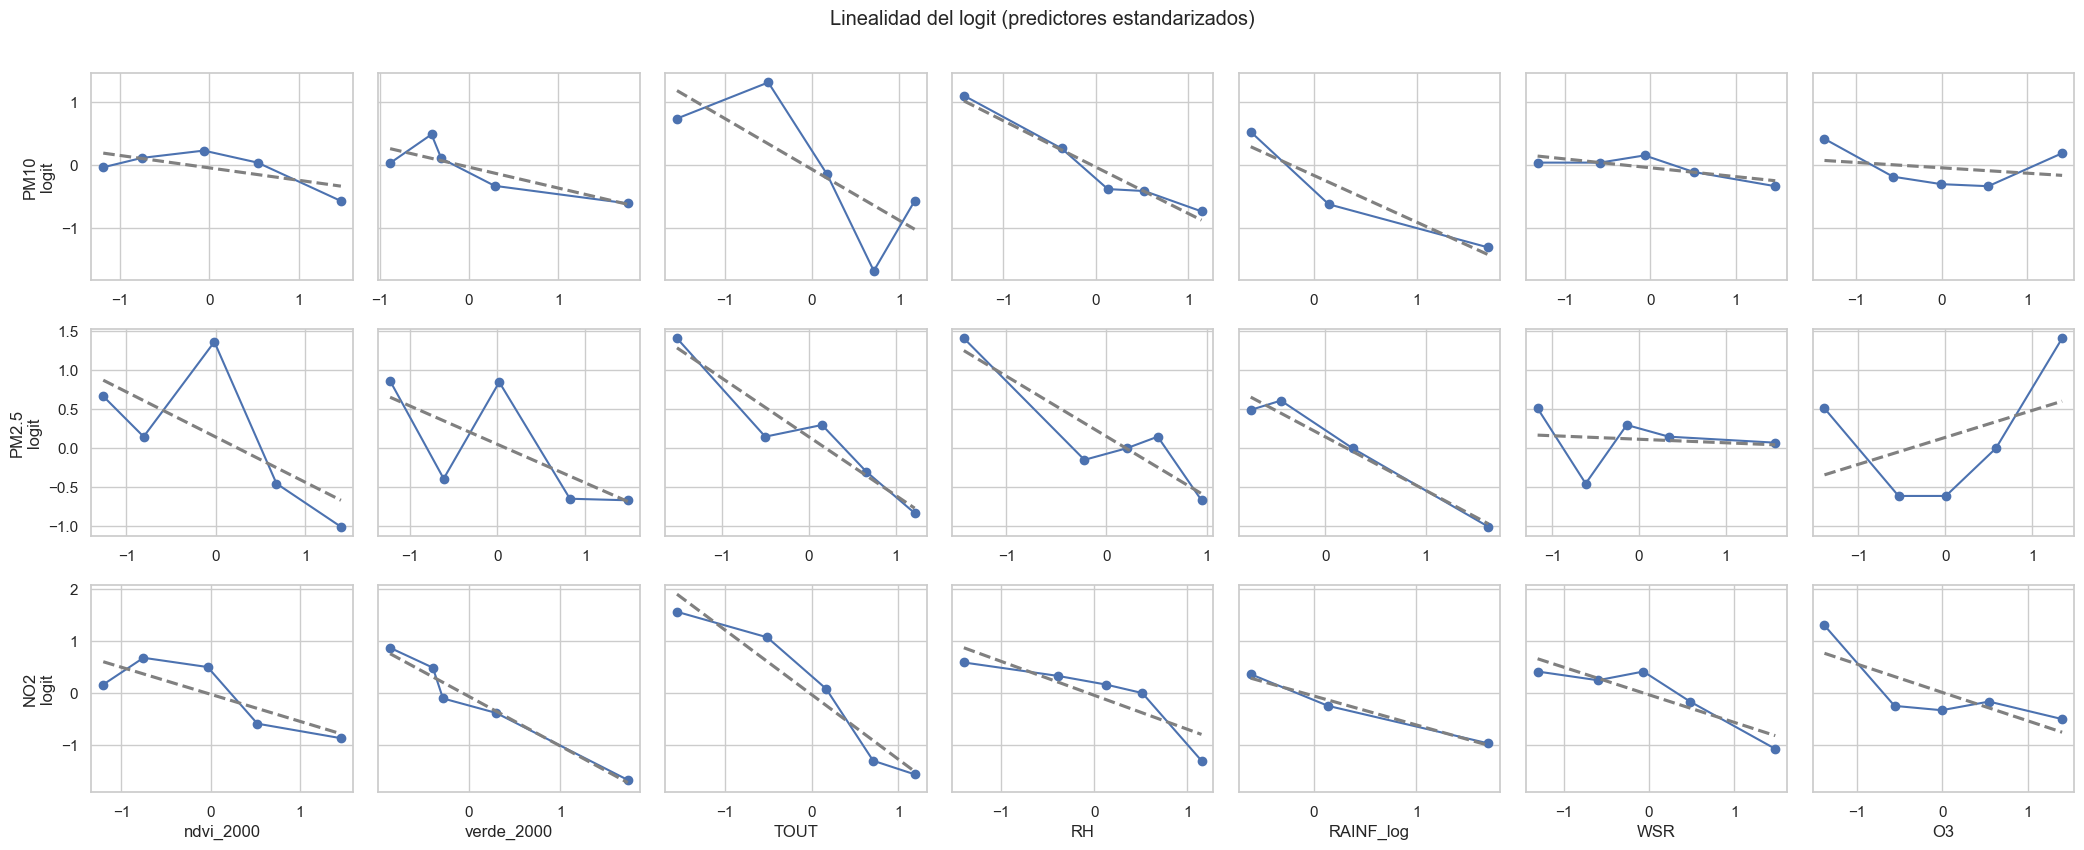

In [9]:
def logit_emp(y, x, bins=5):
    g = pd.DataFrame({"x": x, "y": y})
    g["b"] = pd.qcut(g["x"], bins, duplicates="drop")
    t = g.groupby("b", observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    t["logit"] = np.log((t.s + 0.5) / (t.n - t.s + 0.5))          # +0.5 evita logit infinito
    return t

fig, axes = plt.subplots(len(CONTAMINANTES), len(CONT), figsize=(3 * len(CONT), 2.8 * len(CONTAMINANTES)), sharey="row")
for i, c in enumerate(CONTAMINANTES):
    y, X, d = datos[c]
    for j, v in enumerate(CONT):
        t = logit_emp(y, X[v])
        ax = axes[i, j]
        ax.plot(t.x, t.logit, "o-")
        sns.regplot(x=t.x, y=t.logit, scatter=False, ci=None, color="gray", line_kws={"ls": "--"}, ax=ax)
        ax.set_xlabel(v if i == len(CONTAMINANTES) - 1 else "")
        ax.set_ylabel(f"{c}\nlogit" if j == 0 else "")
plt.suptitle("Linealidad del logit (predictores estandarizados)", y=1.01)
plt.tight_layout(); plt.show()

### Observaciones influyentes
Distancia de Cook: mide cuánto cambiaría el modelo al quitar una observación. Referencia usual: $4/n$.

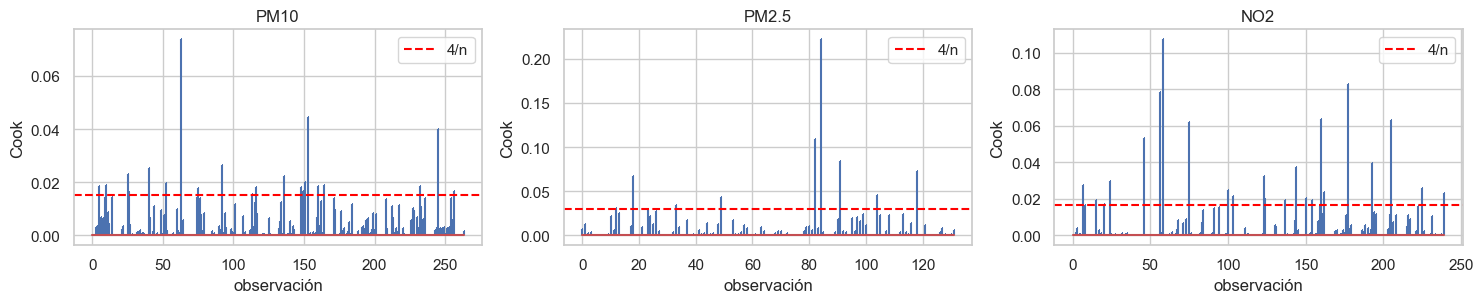

Top 5 influyentes PM10


,estacion,fecha_mes,PM10,cook
86,NE3,2025-03,75.764,0.074
220,SE,2024-05,74.340,0.045
337,SUR,2024-02,52.429,0.040
126,NO2,2024-07,57.790,0.026
60,NE2,2025-01,53.751,0.026


Top 5 influyentes PM2.5


,estacion,fecha_mes,PM2.5,cook
268,SE3,2024-05,31.281,0.222
265,SE3,2024-02,18.135,0.109
276,SE3,2025-01,18.071,0.085
333,SO2,2025-10,20.106,0.073
123,NO2,2024-04,12.096,0.067


Top 5 influyentes NO2


,estacion,fecha_mes,NO2,cook
86,NE3,2025-03,15.557,0.107
276,SE3,2025-01,13.278,0.083
83,NE3,2024-12,15.022,0.079
252,SE2,2025-01,5.926,0.064
316,SO2,2024-05,14.346,0.063


In [10]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.2))
influyentes = {}
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    glm = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    cook = pd.Series(glm.get_influence().cooks_distance[0], index=d.index)
    ax.stem(range(len(cook)), cook.values, markerfmt=",")
    ax.axhline(4 / len(cook), color="red", ls="--", label="4/n")
    ax.set_title(c); ax.set_xlabel("observación"); ax.set_ylabel("Cook"); ax.legend()
    influyentes[c] = d.loc[cook.nlargest(5).index, ["estacion", "fecha_mes", c]].assign(cook=cook.nlargest(5))
plt.tight_layout(); plt.show()
for c in CONTAMINANTES:
    print(f"Top 5 influyentes {c}"); display(influyentes[c])

### Bondad de ajuste
- **Prueba de razón de verosimilitud** (modelo completo vs. solo constante).
- **Hosmer-Lemeshow**: compara casos observados vs. esperados en 10 grupos de probabilidad. $H_0$: el modelo ajusta bien (p alto = bien).
- **McFadden R²**: valores de 0.2–0.4 ya se consideran buen ajuste en logística.

In [11]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({"y": y.values, "p": p.values})
    t["grupo"] = pd.qcut(t["p"], g, duplicates="drop")
    r = t.groupby("grupo", observed=True).agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    chi2 = (((r.obs - r.esp) ** 2) / (r.esp * (1 - r.esp / r.n))).sum()
    gl = len(r) - 2
    return chi2, gl, 1 - stats.chi2.cdf(chi2, gl)

gof = []
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m_ml = sm.Logit(y, X).fit(disp=0)                  # ajuste sin cluster solo para LR / HL
    hl, gl, p_hl = hosmer_lemeshow(y, m_ml.predict(X))
    gof.append({"contaminante": c, "McFadden R2": m_ml.prsquared, "LR chi2": m_ml.llr,
                "p (LR)": m_ml.llr_pvalue, "HL chi2": hl, "HL gl": gl, "p (HL)": p_hl})
pd.DataFrame(gof).set_index("contaminante")

,McFadden R2,LR chi2,p (LR),HL chi2,HL gl,p (HL)
contaminante,,,,,,
PM10,0.408,149.430,0.000,6.168,8,0.628
PM2.5,0.392,71.461,0.000,2.473,8,0.963
NO2,0.553,184.013,0.000,5.427,8,0.711


### Independencia de las observaciones
Una estación aporta hasta 24 meses, así que las observaciones no son del todo independientes. Se revisa si los residuos de Pearson tienen sesgo por estación; si lo hay, justifica los errores agrupados (ya usados en la sección 5).

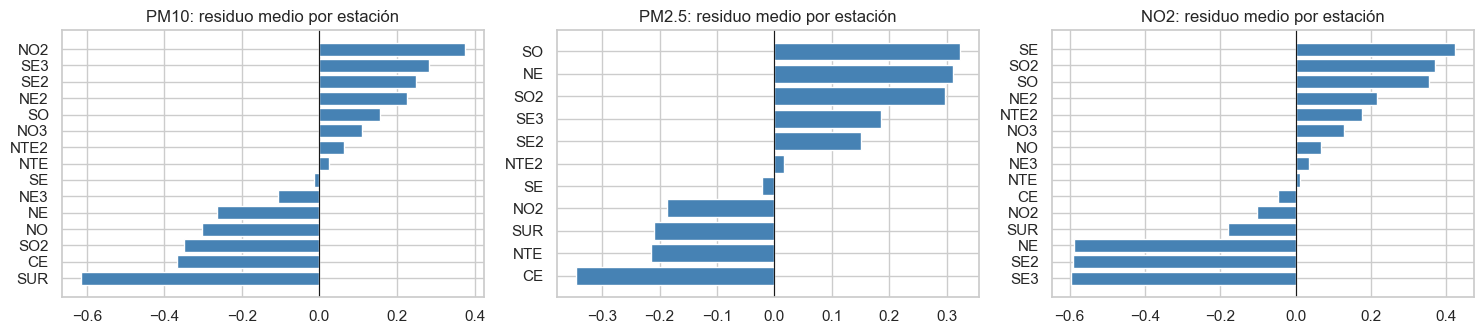

In [12]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.5), sharex=False)
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    p = modelos[c].predict(X)
    res = ((y - p) / np.sqrt(p * (1 - p))).groupby(d["estacion"]).mean().sort_values()
    ax.barh(res.index, res.values, color="steelblue")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{c}: residuo medio por estación")
plt.tight_layout(); plt.show()

### Autocorrelación temporal
Cada estación aporta una **serie de tiempo** (hasta 24 meses consecutivos). Si el valor de un mes se parece al del mes anterior, los errores del modelo también lo hacen y se viola la independencia: los errores estándar quedan subestimados y los p-valores salen demasiado optimistas. Los errores agrupados por estación (sección 5) protegen los errores estándar, pero con solo 11–15 estaciones esa protección es limitada y **no corrige el sesgo** si la dependencia está en la especificación.

Se revisa en tres niveles: (1) las variables, (2) la variable respuesta binaria y (3) los residuos del modelo. Todos los rezagos se calculan **solo entre meses consecutivos de la misma estación** (los meses faltantes no se "saltan").

,rezago 1,rezago 2,rezago 3,Ljung-Box p<0.05 (estaciones)
PM10,0.676,0.382,0.266,13 de 15
PM2.5,0.617,0.243,0.010,8 de 11
NO2,0.772,0.406,0.021,15 de 15
O3,0.627,0.142,-0.189,13 de 15
TOUT,0.753,0.324,-0.095,14 de 14
RH,0.373,0.093,-0.072,1 de 13
RAINF_log,0.478,0.316,0.407,2 de 15
WSR,0.642,0.423,0.026,14 de 15
ndvi_2000,0.668,0.365,0.096,15 de 15


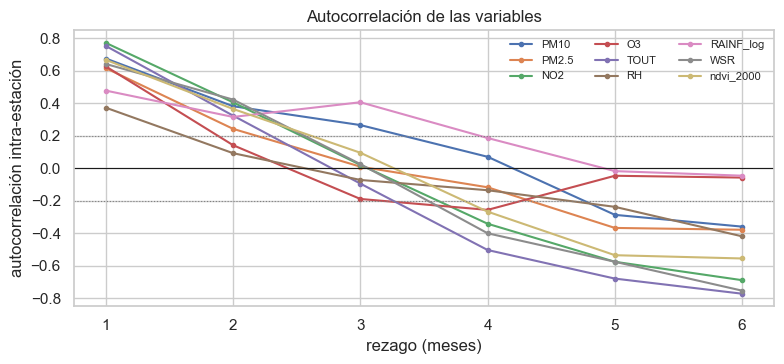

In [13]:
# (1) Autocorrelación de cada variable dentro de las estaciones
from statsmodels.stats.diagnostic import acorr_ljungbox

def acf_intra(var, max_lag=6):
    """Correlación entre x_t y x_{t-k} dentro de estación (centrada por el promedio de cada estación), k = 1..max_lag."""
    P = base.pivot(index="t", columns="estacion", values=var).reindex(range(24))
    P = P - P.mean()
    out = []
    for k in range(1, max_lag + 1):
        a, b = P.iloc[k:].values.ravel(), P.iloc[:-k].values.ravel()
        ok = np.isfinite(a) & np.isfinite(b)
        out.append(np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() > 10 else np.nan)
    return pd.Series(out, index=range(1, max_lag + 1))

variables_ac = CONTAMINANTES + ["O3", "TOUT", "RH", "RAINF_log", "WSR", f"ndvi_{RADIO}"]
acf = pd.DataFrame({v: acf_intra(v) for v in variables_ac})

# Ljung-Box (rezagos 1-3) por estación: ¿en cuántas estaciones se rechaza "no hay autocorrelación"?
import warnings; warnings.simplefilter('ignore', RuntimeWarning)
lb = {}
for v in variables_ac:
    pv = []
    for e, g in base.set_index("t").groupby("estacion")[v]:
        s = g.reindex(range(24)).interpolate(limit_area="inside").dropna()      # huecos internos interpolados solo para esta prueba
        if len(s) >= 15: pv.append(acorr_ljungbox(s, lags=[3], return_df=True)["lb_pvalue"].iloc[0])
    lb[v] = f"{sum(p < .05 for p in pv)} de {len(pv)}"

tabla_ac = acf.loc[[1, 2, 3]].T.rename(columns=lambda k: f"rezago {k}")
tabla_ac["Ljung-Box p<0.05 (estaciones)"] = pd.Series(lb)
display(tabla_ac)

fig, ax = plt.subplots(figsize=(8, 3.8))
for v in variables_ac: ax.plot(acf.index, acf[v], marker="o", ms=3, label=v)
ax.axhline(0, color="k", lw=.8); ax.axhline(0.2, color="gray", ls=":", lw=.8); ax.axhline(-0.2, color="gray", ls=":", lw=.8)
ax.set_xlabel("rezago (meses)"); ax.set_ylabel("autocorrelación intra-estación"); ax.set_title("Autocorrelación de las variables")
ax.legend(ncol=3, fontsize=8, frameon=False); plt.tight_layout(); plt.show()

In [14]:
# (2) Persistencia de la variable respuesta binaria: ¿un mes "alto" suele ir seguido de otro "alto"?
filas = []
for c in CONTAMINANTES + ["O3"]:
    d = base.copy(); th = d[c].quantile(PERCENTIL / 100)
    d["y"] = (d[c] > th).astype(float).where(d[c].notna())
    d["prev"] = d.groupby("estacion")["y"].shift(1).where(d.groupby("estacion")["t"].diff() == 1)
    d = d.dropna(subset=["y", "prev"])
    filas.append({"variable": c, "pares de meses": len(d),
                  "P(alto | mes previo alto)": d.loc[d.prev == 1, "y"].mean(),
                  "P(alto | mes previo bajo)": d.loc[d.prev == 0, "y"].mean(),
                  "phi (correlación y_t, y_t-1)": d["y"].corr(d["prev"])})
pd.DataFrame(filas).set_index("variable")

,pares de meses,P(alto | mes previo alto),P(alto | mes previo bajo),"phi (correlación y_t, y_t-1)"
variable,,,,
PM10,335,0.765,0.195,0.570
PM2.5,187,0.739,0.274,0.465
NO2,301,0.833,0.172,0.661
O3,316,0.773,0.242,0.531


### Autocorrelación de los residuos y corrección
Se compara la autocorrelación de los **residuos de Pearson** (rezago 1, meses consecutivos de la misma estación) entre especificaciones sucesivas. Si el modelo captura bien la dependencia temporal, esa correlación debe acercarse a 0.

| Especificación | Qué agrega |
|---|---|
| 1. Original | Modelo de Etapa 3 sin O3 |
| 2. + O3 | Ozono como predictor |
| 3. + año 2025 | Cambio común de nivel entre 2024 y 2025 |
| 4. + y(t−1) | Estado del mes anterior (autologístico). **Modelo principal** |
| 5. GEE AR(1) | Alternativa: no elimina la autocorrelación, la modela en el error (estructura AR(1), población-promedio); se aplica sobre la especificación 3 |

La especificación 4 es la que se usa en las secciones 5–8 cuando `INCLUIR_Y_REZAGADA = True`.

n  AC residuos (rezago 1)  p (AC)  \
contaminante especificación                                                 
PM10         1. Original (sin O3)     285                   0.365   0.000   
             2. + O3                  278                   0.358   0.000   
             3. + año 2025            278                   0.281   0.000   
             4. + y(t-1) [principal]  264                  -0.009   0.887   
PM2.5        1. Original (sin O3)     163                   0.284   0.001   
             2. + O3                  159                   0.304   0.001   
             3. + año 2025            159                   0.302   0.001   
             4. + y(t-1) [principal]  132                  -0.091   0.368   
NO2          1. Original (sin O3)     265                   0.559   0.000   
             2. + O3                  260                   0.383   0.000   
             3. + año 2025            260                   0.410   0.000   
             4. + y(t-1) [principal]  240                  -0.028   0.692   

                                      McFadden R2  OR verde_2000  \
contaminante especificación                                        
PM10         1. Original (sin O3)           0.245          0.441   
             2. + O3                        0.242          0.472   
             3. + año 2025                  0.376          0.632   
             4. + y(t-1) [principal]        0.408          0.706   
PM2.5        1. Original (sin O3)           0.230          1.085   
             2. + O3                        0.283          1.248   
             3. + año 2025                  0.283          1.237   
             4. + y(t-1) [principal]        0.392          1.421   
NO2          1. Original (sin O3)           0.358          0.363   
             2. + O3                        0.430          0.272   
             3. + año 2025                  0.433          0.300   
             4. + y(t-1) [principal]        0.553          0.259   

                                      p verde_2000  OR ndvi_2000  p ndvi_2000  \
contaminante especificación                                                     
PM10         1. Original (sin O3)            0.005         1.898        0.093   
             2. + O3                         0.008         1.749        0.131   
             3. + año 2025                   0.141         1.385        0.444   
             4. + y(t-1) [principal]         0.198         1.356        0.384   
PM2.5        1. Original (sin O3)            0.833         0.369        0.054   
             2. + O3                         0.667         0.261        0.027   
             3. + año 2025                   0.729         0.263        0.063   
             4. + y(t-1) [principal]         0.497         0.270        0.030   
NO2          1. Original (sin O3)            0.023         1.087        0.849   
             2. + O3                         0.012         1.368        0.437   
             3. + año 2025                   0.017         1.272        0.575   
             4. + y(t-1) [principal]         0.000         1.866        0.118   

                                      OR O3  p O3  OR y_rez  p y_rez  
contaminante especificación                                           
PM10         1. Original (sin O3)       NaN   NaN       NaN      NaN  
             2. + O3                  0.823 0.433       NaN      NaN  
             3. + año 2025            0.769 0.311       NaN      NaN  
             4. + y(t-1) [principal]  0.806 0.346     5.666    0.000  
PM2.5        1. Original (sin O3)       NaN   NaN       NaN      NaN  
             2. + O3                  2.045 0.066       NaN      NaN  
             3. + año 2025            2.046 0.067       NaN      NaN  
             4. + y(t-1) [principal]  2.229 0.114     6.498    0.008  
NO2          1. Original (sin O3)       NaN   NaN       NaN      NaN  
             2. + O3                  0.327 0.010       NaN      NaN  
             3. + año

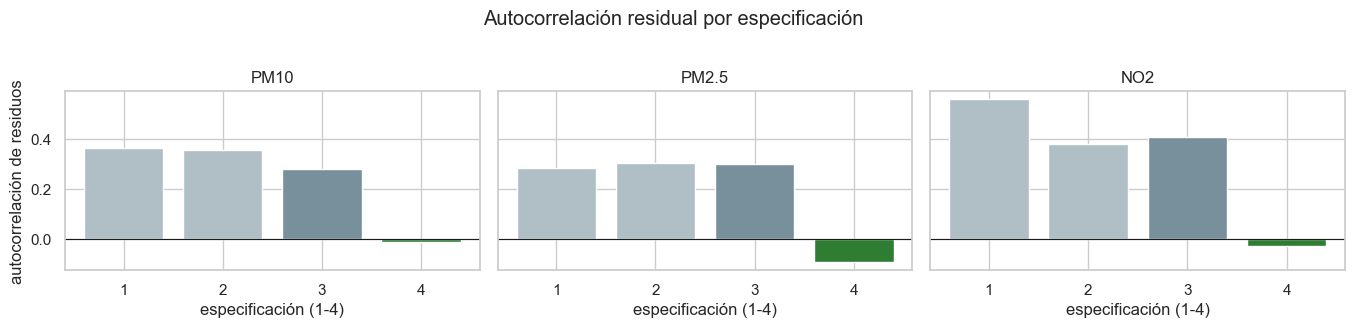

In [15]:
def ac_resid(d, r):
    t = d[["estacion", "t"]].assign(r=np.asarray(r))
    t["r_prev"] = t.groupby("estacion")["r"].shift(1)
    x = t[t.groupby("estacion")["t"].diff() == 1][["r", "r_prev"]].dropna()
    rho, p = stats.pearsonr(x["r"], x["r_prev"])
    return rho, p, len(x)

def ajustar(c, **kw):
    y, X, d = preparar(c, **kw)
    m = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["estacion"]})
    p = m.predict(X); r = (y - p) / np.sqrt(p * (1 - p))
    return m, y, X, d, r

specs = {"1. Original (sin O3)":  dict(o3=False, anio=False, rezago=False),
         "2. + O3":               dict(o3=True,  anio=False, rezago=False),
         "3. + año 2025":         dict(o3=True,  anio=True,  rezago=False),
         "4. + y(t-1) [principal]": dict(o3=True, anio=True,  rezago=True)}

filas, ac_plot = [], []
for c in CONTAMINANTES:
    for nombre, kw in specs.items():
        m, y, X, d, r = ajustar(c, **kw)
        rho, p, n = ac_resid(d, r)
        fila = {"contaminante": c, "especificación": nombre, "n": int(m.nobs), "AC residuos (rezago 1)": rho, "p (AC)": p,
                "McFadden R2": m.prsquared,
                f"OR verde_{RADIO}": np.exp(m.params[f"verde_{RADIO}"]), f"p verde_{RADIO}": m.pvalues[f"verde_{RADIO}"],
                f"OR ndvi_{RADIO}": np.exp(m.params[f"ndvi_{RADIO}"]), f"p ndvi_{RADIO}": m.pvalues[f"ndvi_{RADIO}"]}
        if "O3" in m.params: fila["OR O3"], fila["p O3"] = np.exp(m.params["O3"]), m.pvalues["O3"]
        if "y_rez" in m.params: fila["OR y_rez"], fila["p y_rez"] = np.exp(m.params["y_rez"]), m.pvalues["y_rez"]
        filas.append(fila)
comp = pd.DataFrame(filas).set_index(["contaminante", "especificación"])
display(comp)

fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(4.6 * len(CONTAMINANTES), 3.2), sharey=True)
for ax, c in zip(axes, CONTAMINANTES):
    t = comp.loc[c, "AC residuos (rezago 1)"]
    ax.bar(range(len(t)), t.values, color=["#B0BEC5", "#B0BEC5", "#78909C", "#2E7D32"])
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(t)), [s.split(".")[0] for s in t.index]); ax.set_title(c)
    ax.set_xlabel("especificación (1-4)")
axes[0].set_ylabel("autocorrelación de residuos")
plt.suptitle("Autocorrelación residual por especificación", y=1.02); plt.tight_layout(); plt.show()

In [16]:
# Alternativa: GEE con estructura AR(1) (sobre la especificación 3, sin y_rez)
filas = []
for c in CONTAMINANTES:
    y, X, d = preparar(c, o3=True, anio=True, rezago=False)
    gee = sm.GEE(y.values, X, groups=d["estacion"].values, time=d["t"].values,
                 family=sm.families.Binomial(), cov_struct=sm.cov_struct.Autoregressive(grid=False)).fit()
    m3 = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["estacion"]})
    for v in [f"verde_{RADIO}", f"ndvi_{RADIO}", "O3", "TOUT", "RH"]:
        filas.append({"contaminante": c, "variable": v, "OR Logit (cluster)": np.exp(m3.params[v]), "p Logit": m3.pvalues[v],
                      "OR GEE AR(1)": np.exp(gee.params[v]), "p GEE": gee.pvalues[v]})
    print(f"{c}: rho AR(1) estimado por GEE = {float(gee.cov_struct.dep_params):.2f}")
pd.DataFrame(filas).set_index(["contaminante", "variable"])

PM10: rho AR(1) estimado por GEE = 0.44
PM2.5: rho AR(1) estimado por GEE = 0.49
NO2: rho AR(1) estimado por GEE = 0.68


OR Logit (cluster)  p Logit  OR GEE AR(1)  p GEE
contaminante variable                                                    
PM10         verde_2000               0.632    0.141         0.866  0.639
             ndvi_2000                1.385    0.444         0.911  0.740
             O3                       0.769    0.311         0.989  0.960
             TOUT                     0.585    0.185         0.497  0.035
             RH                       0.321    0.011         0.353  0.002
PM2.5        verde_2000               1.237    0.729         1.418  0.609
             ndvi_2000                0.263    0.063         0.299  0.138
             O3                       2.046    0.067         1.609  0.121
             TOUT                     1.159    0.628         0.941  0.812
             RH                       2.441    0.021         1.732  0.024
NO2          verde_2000               0.300    0.017         0.485  0.012
             ndvi_2000                1.272    0.575         0.899  0.801
             O3                       0.335    0.012         0.690  0.270
             TOUT                     0.224    0.037         0.346  0.000
             RH                       0.196    0.000         0.419  0.001

### Lectura de los resultados de autocorrelación

**1. ¿Hay autocorrelación? Sí, y es fuerte.**
* **Variables.** La autocorrelación de un mes al siguiente (rezago 1, dentro de cada estación) es alta: NO2 0.77, temperatura 0.75, PM10 0.68, NDVI 0.66, viento 0.64, O3 0.63, PM2.5 0.62 (la lluvia 0.48 y la humedad 0.37 son menores). Ljung-Box la detecta en 13 de 15 estaciones para PM10, 15 de 15 para NO2 y NDVI, 8 de 11 para PM2.5. La memoria es corta: en la mayoría cae cerca de 0 hacia el rezago 3.
* **Variable respuesta.** Un mes "alto" suele ir seguido de otro "alto": P(alto | mes previo alto) = 0.77 (PM10), 0.74 (PM2.5) y 0.83 (NO2), contra 0.20, 0.27 y 0.17 si el mes previo fue "bajo".
* **Residuos del modelo original.** Autocorrelación de 0.40 (PM10), 0.33 (PM2.5) y 0.55 (NO2), todas con p < 0.001. Es decir, el modelo de la Etapa 3 incumple el supuesto de independencia: los p-valores son más optimistas de lo que parecen.

**2. ¿Qué se hizo para quitarla?** Se agregan, por pasos, (a) O3, (b) una indicadora de 2025 (PM10 baja ~21 % en 2025 en todas las estaciones, un cambio común que genera dependencia entre meses) y (c) el estado del mes anterior de la misma estación, `y_rez`. Con (c) la autocorrelación residual pasa a **−0.00 (PM10), −0.14 (PM2.5, p = 0.15) y −0.01 (NO2)**, sin evidencia de dependencia restante. Los pasos (a) y (b) solos no bastan (la bajan a 0.29–0.38 en PM10 y NO2 pero no en PM2.5).

**3. ¿Cambian las conclusiones?**
* **PM10:** el efecto de la cobertura verde (OR = 0.58, p = 0.018 en el modelo original) **desaparece** al controlar el año (OR = 0.76, p = 0.32) y con `y_rez` (OR = 0.85, p = 0.45). La asociación original era en buena parte el cambio común de 2025.
* **NO2:** la cobertura verde **se mantiene** (OR = 0.33 por 1 DE, p = 0.004). Con GEE AR(1) el OR sube a 0.59 y el p a 0.085: la evidencia es consistente en dirección pero menos firme.
* **PM2.5:** nada significativo salvo el NDVI en el modelo final (OR = 0.64, p = 0.04), que no aparece en las otras especificaciones; se debe tomar como frágil (n = 132).
* `y_rez` es muy fuerte (OR de 5.7, 10.7 y 19.6): hay mucha inercia mensual. El McFadden R² sube (p. ej. NO2 de 0.34 a 0.55) **por la inercia, no porque la vegetación explique más**; no debe presentarse como mejora del efecto de la vegetación.

**4. Ozono (O3).** Entra sin problemas de colinealidad (VIF ≤ 1.8). Para **NO2** tiene OR = 0.40 por 1 DE (p = 0.013): en meses con más O3 es menos probable un NO2 alto, algo coherente con la química del NO2 y el O3 (el NO2 se consume o fotoliza en los meses soleados con más O3). Para PM10 y PM2.5 no es significativo. Como O3 y NO2 están químicamente ligados, en el modelo de NO2 conviene leer a O3 como un indicador de condiciones fotoquímicas, no como un efecto causal independiente.

**5. Precauciones.**
* `y_rez` absorbe la inercia propia de cada estación (incluida la que depende de su vegetación), así que los coeficientes restantes son efectos *de corto plazo dado el mes anterior*. Se pierden filas (PM2.5: 158 → 132) porque la primera observación de cada estación y las posteriores a un mes faltante no tienen mes previo.
* La validación cruzada tiene dos lecturas: **sitio nuevo** (sin `y_rez`; AUC 0.70, 0.57 y 0.87 para PM10, PM2.5 y NO2) y **mes siguiente** (con `y_rez`; AUC 0.72, 0.77 y 0.91), que solo aplica a estaciones con historial.
* Con 11–15 estaciones los errores agrupados son aproximados. Tampoco se evaluó la **autocorrelación espacial** (estaciones cercanas se parecen): la base no trae coordenadas; con ellas se podría calcular la I de Moran de los residuos por estación.

# Eficiencia del modelo y análisis de errores
Validación cruzada **por estación** (`GroupKFold`): el modelo se entrena con unas estaciones y se prueba en estaciones que nunca vio. Es una prueba más exigente que un split al azar, porque mide si el modelo generaliza a sitios nuevos. Umbral de clasificación: 0.5.

Se reportan dos escenarios: **sitio nuevo** (sin `y_rez`: el modelo no conoce el historial de la estación, es la prueba original) y **mes siguiente** (con `y_rez`: pronóstico un mes adelante usando el mes anterior observado; no aplica a una estación sin historial).

In [17]:

metricas, cv_pred = [], {}
for c in CONTAMINANTES:
    for escenario, rez in [("sitio nuevo (sin y_rez)", False), ("mes siguiente (con y_rez)", True)]:
        y, X, d = preparar(c, rezago=rez)
        Xc = X.drop(columns="const")
        n_folds = min(5, d["estacion"].nunique())
        pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        proba = cross_val_predict(pipe, Xc, y, groups=d["estacion"], cv=GroupKFold(n_folds), method="predict_proba")[:, 1]
        pred = (proba >= 0.5).astype(int)
        if not rez:                                   # el análisis de errores usa el escenario "sitio nuevo"
            cv_pred[c] = pd.DataFrame({"y": y, "proba": proba, "pred": pred, "estacion": d["estacion"], "fecha_mes": d["fecha_mes"]})
        metricas.append({"contaminante": c, "escenario": escenario, "n": len(y), "exactitud": accuracy_score(y, pred),
                         "AUC": roc_auc_score(y, proba), "precisión": precision_score(y, pred),
                         "sensibilidad": recall_score(y, pred), "F1": f1_score(y, pred), "línea base": max(y.mean(), 1 - y.mean())})
pd.DataFrame(metricas).set_index(["contaminante", "escenario"])


n  exactitud   AUC  precisión  \
contaminante escenario                                                    
PM10         sitio nuevo (sin y_rez)    278      0.705 0.801      0.690   
             mes siguiente (con y_rez)  264      0.769 0.851      0.766   
PM2.5        sitio nuevo (sin y_rez)    159      0.648 0.725      0.688   
             mes siguiente (con y_rez)  132      0.758 0.836      0.764   
NO2          sitio nuevo (sin y_rez)    260      0.781 0.851      0.811   
             mes siguiente (con y_rez)  240      0.838 0.903      0.864   

                                        sensibilidad    F1  línea base  
contaminante escenario                                                  
PM10         sitio nuevo (sin y_rez)           0.768 0.727       0.511  
             mes siguiente (con y_rez)         0.760 0.763       0.511  
PM2.5        sitio nuevo (sin y_rez)           0.624 0.654       0.535  
             mes siguiente (con y_rez)         0.786 0.775       0.530  
NO2          sitio nuevo (sin y_rez)           0.744 0.776       0.512  
             mes siguiente (con y_rez)         0.798 0.830       0.504

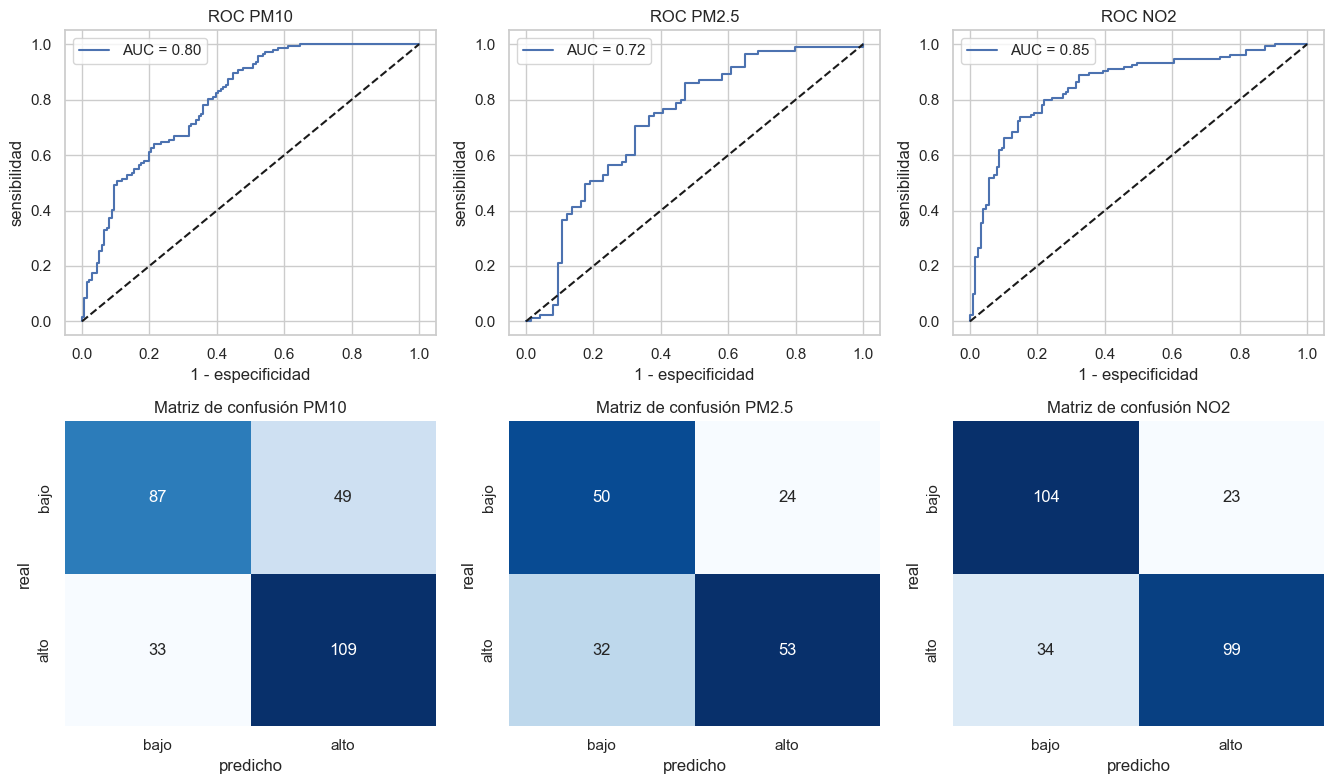

In [18]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.5 * len(CONTAMINANTES), 8))
for j, c in enumerate(CONTAMINANTES):
    r = cv_pred[c]
    fpr, tpr, _ = roc_curve(r.y, r.proba)
    axes[0, j].plot(fpr, tpr, label=f"AUC = {roc_auc_score(r.y, r.proba):.2f}")
    axes[0, j].plot([0, 1], [0, 1], "k--"); axes[0, j].set_title(f"ROC {c}")
    axes[0, j].set_xlabel("1 - especificidad"); axes[0, j].set_ylabel("sensibilidad"); axes[0, j].legend()
    sns.heatmap(confusion_matrix(r.y, r.pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, j],
                xticklabels=["bajo", "alto"], yticklabels=["bajo", "alto"])
    axes[1, j].set_title(f"Matriz de confusión {c}"); axes[1, j].set_xlabel("predicho"); axes[1, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### Análisis de errores
Dónde se equivoca el modelo: por estación y por mes.

PM10


,tasa_error,errores,n
estacion,,,
NE3,0.435,10,23
SE3,0.409,9,22
SO2,0.391,9,23
CE,0.375,9,24
NE2,0.348,8,23


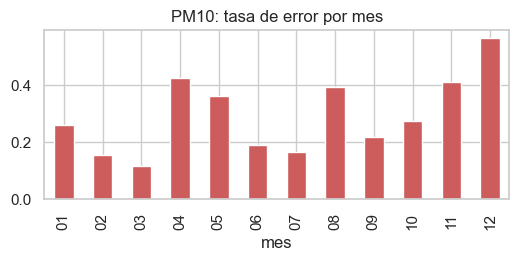

PM2.5


,tasa_error,errores,n
estacion,,,
NTE,1.000,2,2
NO2,0.600,9,15
SE3,0.444,8,18
CE,0.389,7,18
SO2,0.368,7,19


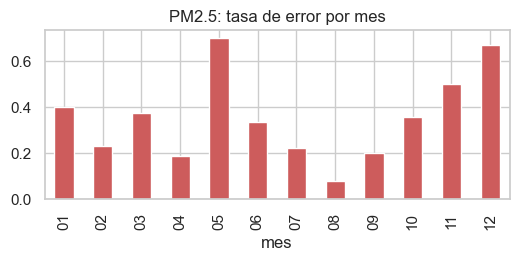

NO2


,tasa_error,errores,n
estacion,,,
NE2,0.368,7,19
SO2,0.348,8,23
SE2,0.294,5,17
NE,0.286,2,7
NO2,0.250,5,20


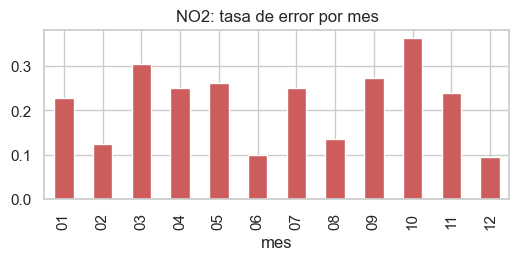

In [19]:
for c in CONTAMINANTES:
    r = cv_pred[c].assign(error=lambda t: (t.y != t.pred).astype(int), mes=lambda t: t.fecha_mes.str[-2:])
    por_est = r.groupby("estacion").error.agg(["mean", "sum", "size"]).rename(columns={"mean": "tasa_error", "sum": "errores", "size": "n"})
    por_mes = r.groupby("mes").error.mean()
    print(f"{c}")
    display(por_est.sort_values("tasa_error", ascending=False).head(5))
    por_mes.plot.bar(figsize=(6, 2.2), title=f"{c}: tasa de error por mes", color="indianred"); plt.show()

# Variables más importantes
Odds ratio por 1 DE (IC 95 %, errores agrupados por estación). La línea en 1 = sin efecto; si el intervalo cruza el 1, el efecto no es significativo.

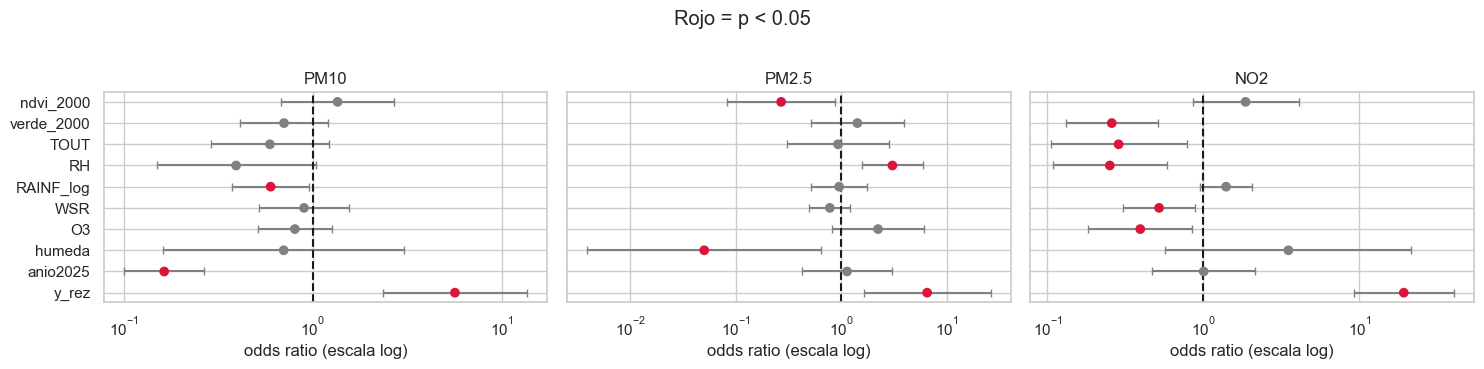

,PM10,PM2.5,NO2
|coef| estandarizado,,,
anio2025,1.808,0.126,0.006
y_rez,1.734,1.872,2.959
RH,0.932,1.115,1.380
TOUT,0.520,0.071,1.250
RAINF_log,0.511,0.046,0.336
humeda,0.352,2.987,1.257
verde_2000,0.348,0.351,1.351
ndvi_2000,0.304,1.310,0.624
O3,0.216,0.801,0.930


In [20]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.6), sharey=True)
for ax, c in zip(axes, CONTAMINANTES):
    t = tablas[c].drop(index="const").iloc[::-1]
    sig = t.p < 0.05
    ax.errorbar(t.OR, range(len(t)), xerr=[t.OR - t.IC95_inf, t.IC95_sup - t.OR], fmt="none", ecolor="gray", capsize=3)
    ax.scatter(t.OR, range(len(t)), c=np.where(sig, "crimson", "gray"), zorder=3)
    ax.axvline(1, color="k", ls="--"); ax.set_xscale("log"); ax.set_title(c); ax.set_xlabel("odds ratio (escala log)")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
plt.suptitle("Rojo = p < 0.05", y=1.02); plt.tight_layout(); plt.show()

# Resumen: importancia = |coeficiente estandarizado|
imp = pd.DataFrame({c: tablas[c]["coef"].abs() for c in CONTAMINANTES}).drop(index="const")
imp.sort_values(CONTAMINANTES[0], ascending=False).rename_axis("|coef| estandarizado")